In [ ]:
import io
import zipfile
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
url = "https://os.unil.cloud.switch.ch/fma/fma_metadata.zip"

with urllib.request.urlopen(url) as response:
    archive_data = response.read()

In [ ]:
with zipfile.ZipFile(io.BytesIO(archive_data)) as archive:
    tracks_file = next(
        name for name in archive.namelist()
        if name.endswith("tracks.csv")
    )

    with archive.open(tracks_file) as file:
        tracks = pd.read_csv(file, header=[0, 1], index_col=0)

print("размер исходной таблицы:", tracks.shape)
tracks.head()

Размер исходной таблицы: (109726, 38)


track_id,album_id,album_title,album_url,artist_id,artist_name,artist_url,artist_website,license_image_file,license_image_file_large,license_parent_id,...,track_information,track_instrumental,track_interest,track_language_code,track_listens,track_lyricist,track_number,track_publisher,track_title,track_url
2,1,AWOL - A Way Of Life,http://freemusicarchive.org/music/AWOL/AWOL_-_A_Way_Of_Life/,1,AWOL,http://freemusicarchive.org/music/AWOL/,http://www.AzillionRecords.blogspot.com,http://i.creativecommons.org/l/by-nc-sa/3.0/us/88x31.png,http://fma-files.s3.amazonaws.com/resources/img/licenses/by-nc-sa.png,5,...,Unnamed: 29_level_1,0,4656,en,1293,Unnamed: 34_level_1,3,Unnamed: 36_level_1,Food,http://freemusicarchive.org/music/AWOL/AWOL_-_A_Way_Of_Life/Food
3,1.0,AWOL - A Way Of Life,http://freemusicarchive.org/music/AWOL/AWOL_-_...,1,AWOL,http://freemusicarchive.org/music/AWOL/,http://www.AzillionRecords.blogspot.com,http://i.creativecommons.org/l/by-nc-sa/3.0/us...,http://fma-files.s3.amazonaws.com/resources/im...,5.0,...,NaN,0,1470,en,514,NaN,4,NaN,Electric Ave,http://freemusicarchive.org/music/AWOL/AWOL_-_...
5,1.0,AWOL - A Way Of Life,http://freemusicarchive.org/music/AWOL/AWOL_-_...,1,AWOL,http://freemusicarchive.org/music/AWOL/,http://www.AzillionRecords.blogspot.com,http://i.creativecommons.org/l/by-nc-sa/3.0/us...,http://fma-files.s3.amazonaws.com/resources/im...,5.0,...,NaN,0,1933,en,1151,NaN,6,NaN,This World,http://freemusicarchive.org/music/AWOL/AWOL_-_...
10,6.0,Constant Hitmaker,http://freemusicarchive.org/music/Kurt_Vile/Co...,6,Kurt Vile,http://freemusicarchive.org/music/Kurt_Vile/,http://kurtvile.com,http://i.creativecommons.org/l/by-nc-nd/3.0/88...,http://fma-files.s3.amazonaws.com/resources/im...,NaN,...,NaN,0,54881,en,50135,NaN,1,NaN,Freeway,http://freemusicarchive.org/music/Kurt_Vile/Co...
20,4.0,Niris,http://freemusicarchive.org/music/Chris_and_Ni...,4,Nicky Cook,http://freemusicarchive.org/music/Chris_and_Ni...,NaN,http://i.creativecommons.org/l/by-nc-nd/3.0/88...,http://fma-files.s3.amazonaws.com/resources/im...,NaN,...,NaN,0,978,en,361,NaN,3,NaN,Spiritual Level,http://freemusicarchive.org/music/Chris_and_Ni...
26,4.0,Niris,http://freemusicarchive.org/music/Chris_and_Ni...,4,Nicky Cook,http://freemusicarchive.org/music/Chris_and_Ni...,NaN,http://i.creativecommons.org/l/by-nc-nd/3.0/88...,http://fma-files.s3.amazonaws.com/resources/im...,NaN,...,NaN,0,1060,en,193,NaN,4,NaN,Where is your Love?,http://freemusicarchive.org/music/Chris_and_Ni...


In [ ]:
columns_true = [
    "track_title",
    "artist_name",
    "track_genres",
    "track_url",
    "track_duration",
    "track_listens",
    "track_datecreated",
]

music = tracks[columns_true].copy()
music = music.rename(columns={
    "track_title": "track_name",
    "artist_name": "artist",
    "track_genres": "genre",
    "track_url": "audio_url",
    "track_duration": "duration",
    "track_listens": "listens",
    "track_datecreated": "date_created",
})

print("кол-во треков:", len(music))
music.head()

Количество треков: 109727


,track_name,artist,genre,audio_url,duration,listens,date_created
track_id,,,,,,,
2,Food,AWOL,"[{'genre_id': '21', 'genre_title': 'Hip-Hop', ...",http://freemusicarchive.org/music/AWOL/AWOL_-_...,02:48,1293,11/26/2008 01:48:12 AM
3,Electric Ave,AWOL,"[{'genre_id': '21', 'genre_title': 'Hip-Hop', ...",http://freemusicarchive.org/music/AWOL/AWOL_-_...,03:57,514,11/26/2008 01:48:14 AM
5,This World,AWOL,"[{'genre_id': '21', 'genre_title': 'Hip-Hop', ...",http://freemusicarchive.org/music/AWOL/AWOL_-_...,03:26,1151,11/26/2008 01:48:20 AM
10,Freeway,Kurt Vile,"[{'genre_id': '10', 'genre_title': 'Pop', 'gen...",http://freemusicarchive.org/music/Kurt_Vile/Co...,02:41,50135,11/25/2008 05:49:06 PM
20,Spiritual Level,Nicky Cook,"[{'genre_id': '76', 'genre_title': 'Experiment...",http://freemusicarchive.org/music/Chris_and_Ni...,05:11,361,11/26/2008 01:48:56 AM


In [ ]:
print("пропуски по столбцам:")
print(music.isna().sum())

print("кол-во дубликатов:")
print(music.duplicated().sum())

print("кол-во уникальных исполнителей:")
print(music["artist"].nunique())

пропуски по столбцам:
track_name         1
artist             0
genre           2609
audio_url       1041
duration           0
listens            0
date_created       0
dtype: int64
количество дубликатов:
0
количество уникальных исполнителей:
17117


на данном этапе я выявила пропуски в названиях треков, жанров и ссылках, но при этом значения исполнителей, продолжительности и числа прослушиваний заполнены во всех записях
над пропускам в жанрах нужно еще поработать, поскольку это является одним из основных признаков для анализа музыкальных рекомендаций

In [ ]:
import ast

def get_main_genre(value):
    if pd.isna(value):
        return None

    try:
        genres = ast.literal_eval(value)
        if genres:
            return genres[0].get("genre_title")
    except (ValueError, SyntaxError, AttributeError):
        return None

    return None


music["genre"] = music["genre"].apply(get_main_genre)

print(music["genre"].value_counts().head(20))

genre
Electronic            20594
Avant-Garde            9183
Rock                   6904
Experimental           6732
Pop                    6225
Folk                   4343
Hip-Hop                4088
Punk                   3635
Noise                  3345
Soundtrack             3065
Lo-Fi                  2914
Experimental Pop       2020
Jazz                   1902
Classical              1777
International          1755
Blues                  1717
Ambient Electronic     1671
Indie-Rock             1620
Field Recordings       1154
Psych-Rock             1090
Name: count, dtype: int64


In [ ]:
genre_counts = music["genre"].value_counts()

print("кол-во доступных жанров:", len(genre_counts))
print("самые распространенные жанры:")
print(genre_counts.head(15))

Количество доступных жанров: 149

Самые распространённые жанры:
genre
Electronic          20594
Avant-Garde          9183
Rock                 6904
Experimental         6732
Pop                  6225
Folk                 4343
Hip-Hop              4088
Punk                 3635
Noise                3345
Soundtrack           3065
Lo-Fi                2914
Experimental Pop     2020
Jazz                 1902
Classical            1777
International        1755
Name: count, dtype: int64


In [ ]:
import random

random.seed(42)

selected_genres = [
    "Electronic",
    "Rock",
    "Pop",
    "Folk",
    "Hip-Hop",
    "Punk",
    "Jazz",
    "Classical",
]

genre_limits = {
    genre: 13 if i < 4 else 12
    for i, genre in enumerate(selected_genres)
}

candidates = music.dropna(
    subset=["track_name", "artist", "genre", "audio_url"]
).copy()

candidates = candidates.drop_duplicates(
    subset=["track_name", "artist"]
)

candidates = candidates.sample(
    frac=1,
    random_state=42
)

selected_rows = []
artist_counts = {}
genre_counts = {genre: 0 for genre in selected_genres}

for genre in selected_genres:
    genre_tracks = candidates[candidates["genre"] == genre]

    for index, track in genre_tracks.iterrows():
        artist = track["artist"]

        if genre_counts[genre] >= genre_limits[genre]:
            break

        if artist_counts.get(artist, 0) >= 2:
            continue

        selected_rows.append(track)
        genre_counts[genre] += 1
        artist_counts[artist] = artist_counts.get(artist, 0) + 1

dataset = pd.DataFrame(selected_rows).reset_index(drop=True)

dataset.insert(
    0,
    "track_id",
    [f"track_{i:03d}" for i in range(1, len(dataset) + 1)]
)

print("итоговый размер:", len(dataset))
print("распределение по жанрам:")
print(dataset["genre"].value_counts())

dataset.head(10)

итоговый размер: 100
распределение по жанрам:
genre
Electronic    13
Rock          13
Pop           13
Folk          13
Hip-Hop       12
Punk          12
Jazz          12
Classical     12
Name: count, dtype: int64


,track_id,track_name,artist,genre,audio_url,duration,listens,date_created
0,track_001,A qui te me bou,RÉGIS VICTOR,Electronic,http://freemusicarchive.org/music/Rgis_Victor/...,00:38,369,6/19/2010 02:15:58 AM
1,track_002,Dedication for...,Serhio Efremis,Electronic,http://freemusicarchive.org/music/Serhio_Efrem...,02:08,395,6/17/2014 11:35:04 AM
2,track_003,Warm (For A While),Syndrôm,Electronic,http://freemusicarchive.org/music/Syndrm/Galac...,03:12,1085,10/01/2012 03:53:04 PM
3,track_004,Celestical,Sci Fi Industries,Electronic,http://freemusicarchive.org/music/Sci_Fi_Indus...,04:27,605,1/17/2014 09:16:30 AM
4,track_005,Miss Taznif Goes to Town Riding on a Pony,Solomonoff and Von Hoffmannstahl,Electronic,http://freemusicarchive.org/music/Solomonoff_a...,09:46,184,11/26/2008 03:01:26 AM
5,track_006,Djangle,Podington Bear,Electronic,http://freemusicarchive.org/music/Podington_Be...,01:34,2897,4/04/2013 03:46:13 AM
6,track_007,Eroding Tides,Abereiddy Astronomical Society,Electronic,http://freemusicarchive.org/music/Abereiddy_As...,06:08,255,5/06/2014 11:21:34 AM
7,track_008,Gimme a lighta,Jonas,Electronic,http://freemusicarchive.org/music/Jonas/Pindar...,03:38,5211,4/06/2013 06:31:12 AM
8,track_009,Gravity,Sanfeel,Electronic,http://freemusicarchive.org/music/Sanfeel/Grav...,04:29,759,2/13/2017 03:11:06 PM
9,track_010,A Learning Experience,Optional,Electronic,http://freemusicarchive.org/music/Optional/Mid...,07:32,2136,5/02/2016 03:21:00 PM


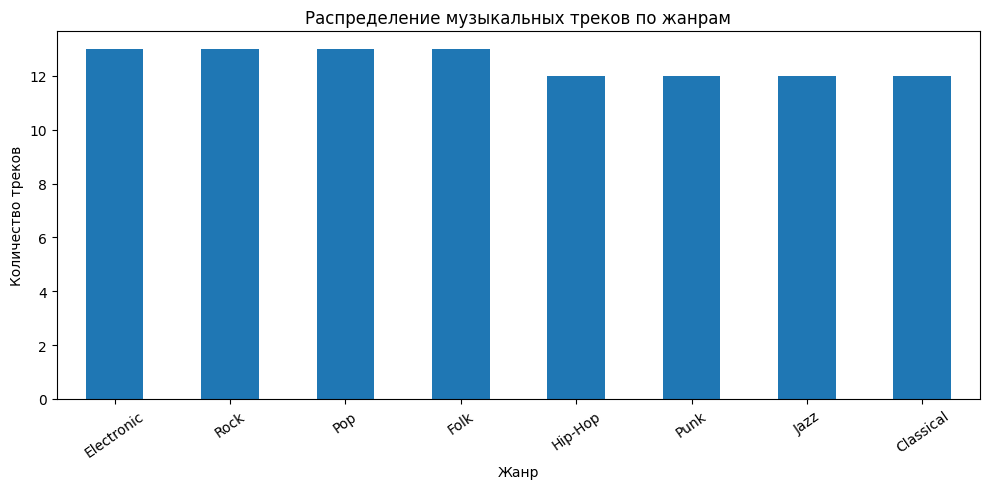

In [ ]:
genre_distribution = dataset["genre"].value_counts()

genre_distribution.plot(
    kind="bar",
    figsize=(10, 5),
    xlabel="жанр",
    ylabel="кол-во треков",
    title="распределение музыкальных треков по жанрам",
    rot=35
)

plt.tight_layout()
plt.show()

In [ ]:
dataset.to_csv(
    "music_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print("датасет сохранен")

датасет сохранен


In [ ]:
duplicates = dataset.duplicated(
    subset=["track_name", "artist"]
).sum()

dataset["source"] = "Free Music Archive (FMA)"

print("Повторяющихся композиций:", duplicates)
print("Количество треков:", len(dataset))
print("Количество жанров:", dataset["genre"].nunique())

dataset.to_csv(
    "music_dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

Повторяющихся композиций: 0
Количество треков: 100
Количество жанров: 8


In [ ]:
from google.colab import files

files.download("music_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

для выборки использовался открытый набор данных Free Music Archive (FMA). на основе была сформирована выборка из 100 музыкальных треков восьми жанров: Electronic, Rock, Pop, Folk, Hip-Hop, Punk, Jazz и Classical и использовалась случайная перестановка записей с фиксированным значением генератора случайных чисел.
на 4 жанра отобрано по 13 композиций, для остальных по 12, кол-во треков одного исполнителя ограничено двумя, а при наличии нескольких жанров у композиции для формирования выборки использовался первый жанр, указанный в исходных метаданных.
результат работы содержит имя треков, исполнителей, жанры, ссылки на страницы композиций, продолжительность, число прослушиваний и дату создания записи.

**2 задание**

In [27]:
print("размер:", dataset.shape)

print("названия:")
print(dataset.columns.tolist())

print("первые 5 треков:")
display(dataset[["track_name", "artist", "genre", "audio_url"]].head())

размер: (100, 9)
названия:
['track_id', 'track_name', 'artist', 'genre', 'audio_url', 'duration', 'listens', 'date_created', 'source']
первые 5 треков:


,track_name,artist,genre,audio_url
0,A qui te me bou,RÉGIS VICTOR,Electronic,http://freemusicarchive.org/music/Rgis_Victor/...
1,Dedication for...,Serhio Efremis,Electronic,http://freemusicarchive.org/music/Serhio_Efrem...
2,Warm (For A While),Syndrôm,Electronic,http://freemusicarchive.org/music/Syndrm/Galac...
3,Celestical,Sci Fi Industries,Electronic,http://freemusicarchive.org/music/Sci_Fi_Indus...
4,Miss Taznif Goes to Town Riding on a Pony,Solomonoff and Von Hoffmannstahl,Electronic,http://freemusicarchive.org/music/Solomonoff_a...


In [28]:
dataset["opisanie"] = (
    "Track: " + dataset["track_name"].fillna("") +
    ". Artist: " + dataset["artist"].fillna("") +
    ". Genre: " + dataset["genre"].fillna("")
)

display(dataset[["track_name", "artist", "genre", "opisanie"]].head())

,track_name,artist,genre,opisanie
0,A qui te me bou,RÉGIS VICTOR,Electronic,Track: A qui te me bou. Artist: RÉGIS VICTOR. ...
1,Dedication for...,Serhio Efremis,Electronic,Track: Dedication for.... Artist: Serhio Efrem...
2,Warm (For A While),Syndrôm,Electronic,Track: Warm (For A While). Artist: Syndrôm. Ge...
3,Celestical,Sci Fi Industries,Electronic,Track: Celestical. Artist: Sci Fi Industries. ...
4,Miss Taznif Goes to Town Riding on a Pony,Solomonoff and Von Hoffmannstahl,Electronic,Track: Miss Taznif Goes to Town Riding on a Po...


In [30]:
!pip -q install transformers

from transformers import pipeline

model = pipeline(
    "zero-shot-classification",
    model="valhalla/distilbart-mnli-12-1"
)

print("уро работает")

Loading weights:   0%|          | 0/231 [00:00<?, ?it/s]

уро работает


In [31]:
nastroeniya = [
    "energetic and lively music",
    "calm and relaxing music",
    "sad and melancholic music",
    "happy and cheerful music",
    "dark and mysterious music"
]

rezultaty = []

for _, trek in dataset.head(5).iterrows():
    otvet = model(
        trek["opisanie"],
        candidate_labels=nastroeniya
    )

    rezultaty.append({
        "track_name": trek["track_name"],
        "artist": trek["artist"],
        "genre": trek["genre"],
        "predicted_mood": otvet["labels"][0],
        "confidence": round(otvet["scores"][0], 3)
    })

import pandas as pd

proverka = pd.DataFrame(rezultaty)
display(proverka)

,track_name,artist,genre,predicted_mood,confidence
0,A qui te me bou,RÉGIS VICTOR,Electronic,energetic and lively music,0.479
1,Dedication for...,Serhio Efremis,Electronic,energetic and lively music,0.436
2,Warm (For A While),Syndrôm,Electronic,happy and cheerful music,0.589
3,Celestical,Sci Fi Industries,Electronic,energetic and lively music,0.541
4,Miss Taznif Goes to Town Riding on a Pony,Solomonoff and Von Hoffmannstahl,Electronic,happy and cheerful music,0.466


In [32]:
nastroeniya = [
    "energetic and lively music",
    "calm and relaxing music",
    "sad and melancholic music",
    "happy and cheerful music",
    "dark and mysterious music"
]

rezultaty = []

for _, trek in dataset.iterrows():
    otvet = model(
        trek["opisanie"],
        candidate_labels=nastroeniya
    )

    rezultaty.append({
        "track_name": trek["track_name"],
        "artist": trek["artist"],
        "genre": trek["genre"],
        "nastroenie": otvet["labels"][0],
        "ocenka_modeli": round(otvet["scores"][0], 3)
    })

dataset["nastroenie"] = [r["nastroenie"] for r in rezultaty]
dataset["ocenka_modeli"] = [r["ocenka_modeli"] for r in rezultaty]

display(dataset[[
    "track_name", "artist", "genre",
    "nastroenie", "ocenka_modeli"
]].head(10))

,track_name,artist,genre,nastroenie,ocenka_modeli
0,A qui te me bou,RÉGIS VICTOR,Electronic,energetic and lively music,0.479
1,Dedication for...,Serhio Efremis,Electronic,energetic and lively music,0.436
2,Warm (For A While),Syndrôm,Electronic,happy and cheerful music,0.589
3,Celestical,Sci Fi Industries,Electronic,energetic and lively music,0.541
4,Miss Taznif Goes to Town Riding on a Pony,Solomonoff and Von Hoffmannstahl,Electronic,happy and cheerful music,0.466
5,Djangle,Podington Bear,Electronic,dark and mysterious music,0.543
6,Eroding Tides,Abereiddy Astronomical Society,Electronic,dark and mysterious music,0.675
7,Gimme a lighta,Jonas,Electronic,energetic and lively music,0.454
8,Gravity,Sanfeel,Electronic,dark and mysterious music,0.616
9,A Learning Experience,Optional,Electronic,energetic and lively music,0.596


In [33]:
dataset.to_csv(
    "music_dataset_with_mood.csv",
    index=False,
    encoding="utf-8-sig"
)

print("датасет готов!!!")

датасет готов!!!


In [34]:
from google.colab import files
files.download("music_dataset_with_mood.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
konteksty = [
    "music for studying and concentration",
    "music for working out and exercise",
    "music for relaxing and resting",
    "music for a party and dancing"
]

rezultaty_konteksta = []

for _, trek in dataset.iterrows():
    otvet = model(
        trek["opisanie"],
        candidate_labels=konteksty
    )

    rezultaty_konteksta.append({
        "kontekst": otvet["labels"][0],
        "ocenka_konteksta": round(otvet["scores"][0], 3)
    })

dataset["kontekst"] = [
    r["kontekst"] for r in rezultaty_konteksta
]

dataset["ocenka_konteksta"] = [
    r["ocenka_konteksta"] for r in rezultaty_konteksta
]

display(dataset[[
    "track_name",
    "genre",
    "nastroenie",
    "kontekst",
    "ocenka_konteksta"
]].head(10))

,track_name,genre,nastroenie,kontekst,ocenka_konteksta
0,A qui te me bou,Electronic,energetic and lively music,music for a party and dancing,0.340
1,Dedication for...,Electronic,energetic and lively music,music for working out and exercise,0.284
2,Warm (For A While),Electronic,happy and cheerful music,music for relaxing and resting,0.689
3,Celestical,Electronic,energetic and lively music,music for a party and dancing,0.312
4,Miss Taznif Goes to Town Riding on a Pony,Electronic,happy and cheerful music,music for a party and dancing,0.574
5,Djangle,Electronic,dark and mysterious music,music for a party and dancing,0.470
6,Eroding Tides,Electronic,dark and mysterious music,music for studying and concentration,0.384
7,Gimme a lighta,Electronic,energetic and lively music,music for a party and dancing,0.389
8,Gravity,Electronic,dark and mysterious music,music for working out and exercise,0.339
9,A Learning Experience,Electronic,energetic and lively music,music for studying and concentration,0.818


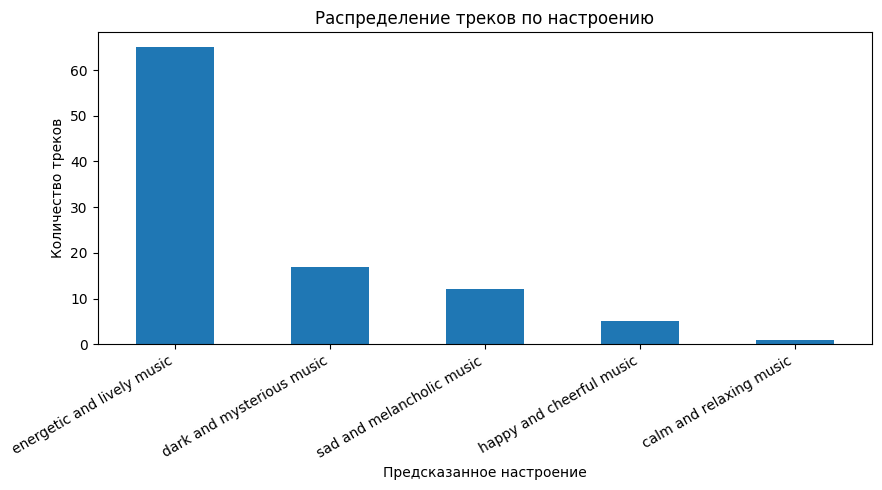

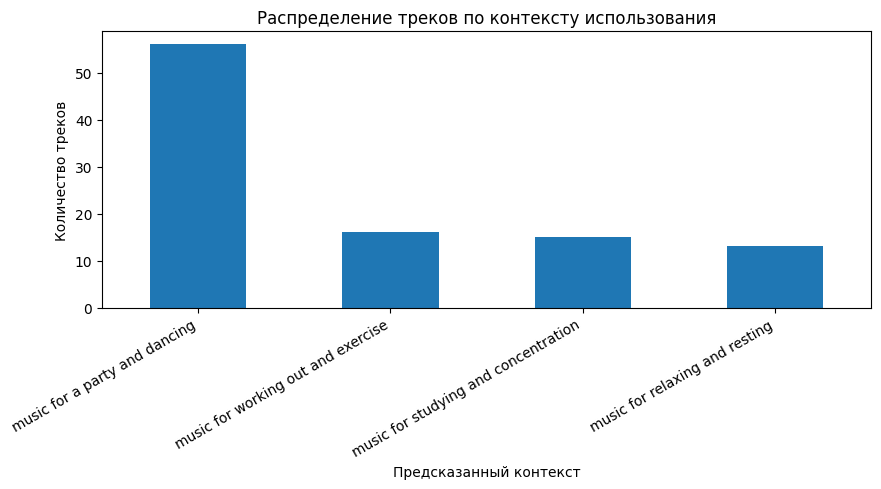

In [36]:
import matplotlib.pyplot as plt

dataset["nastroenie"].value_counts().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Распределение треков по настроению")
plt.xlabel("Предсказанное настроение")
plt.ylabel("Количество треков")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

dataset["kontekst"].value_counts().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Распределение треков по контексту использования")
plt.xlabel("Предсказанный контекст")
plt.ylabel("Количество треков")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [37]:
svyaz_zhanra_i_nastroeniya = pd.crosstab(
    dataset["genre"],
    dataset["nastroenie"]
)

display(svyaz_zhanra_i_nastroeniya)

nastroenie,calm and relaxing music,dark and mysterious music,energetic and lively music,happy and cheerful music,sad and melancholic music
genre,,,,,
Classical,1,2,6,0,3
Electronic,0,4,6,2,1
Folk,0,3,5,2,3
Hip-Hop,0,2,9,1,0
Jazz,0,0,10,0,2
Pop,0,0,10,0,3
Punk,0,2,10,0,0
Rock,0,4,9,0,0


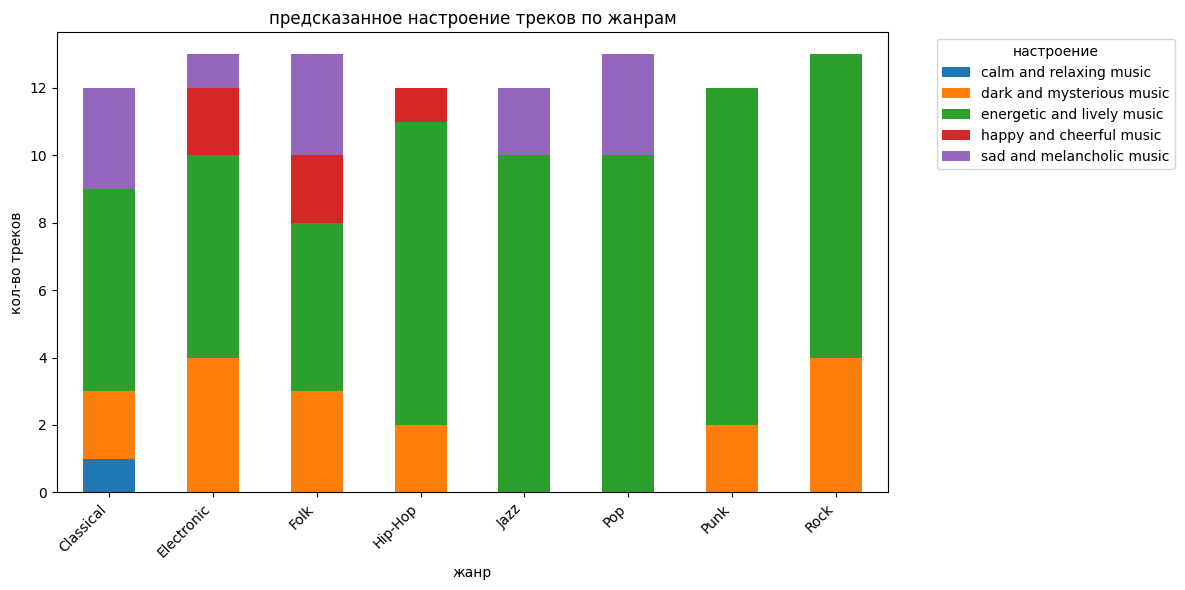

In [38]:
svyaz_zhanra_i_nastroeniya.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("предсказанное настроение треков по жанрам")
plt.xlabel("жанр")
plt.ylabel("кол-во треков")
plt.xticks(rotation=45, ha="right")
plt.legend(title="настроение", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [40]:
dataset.to_csv(
    "music_dataset_final.csv",
    index=False,
    encoding="utf-8-sig"
)

print("япи готово готоговый датасет сохранен.")
print("кол-во треков:", len(dataset))
print("кол-во столбцов:", len(dataset.columns))

япи готово готоговый датасет сохранен.
кол-во треков: 100
кол-во столбцов: 14


In [41]:
from google.colab import files
files.download("music_dataset_final.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
display(
    dataset[[
        "track_name",
        "artist",
        "genre",
        "nastroenie",
        "kontekst"
    ]].isna().sum()
)

,0
track_name,0
artist,0
genre,0
nastroenie,0
kontekst,0


сформирован набор из 100 музыкальных треков из открытого источника Free Music Archive, использовались метаданные для каждого трека: название, исполнитель и жанр.

на основе текстового описания каждого трека модель предсказала два дополнительных признака:
1. Настроение: энергичное, спокойное, грустное, веселое и тп
2. Контекст: учеба, тренировка, отдых, вечеринка
для настроения и контекста также рассчитаны оценки модели, показывающие предпочтение выбранной категории среди предложенных вариантов.

модель анализировала названия треков, имена исполнителей и жанры, но не записи, требуется требуется дополнительная оценка, например, прослушивание части треков.

работа может использоваться в рекомендательной системе для группировки и предварительного подбора музыки по предполагаемому настроению и контексту